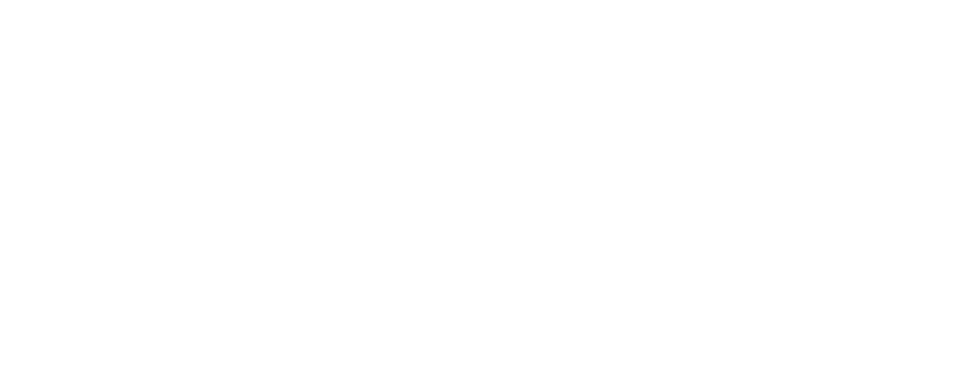

# Inhaltsverzeichnis

1. Wie das Internet spricht (APIs & JSON)
2. Requests in Python
3. Parameter und API-Keys
4. Pagination

# Das Ziel (Spoiler):

Bisher war dein Python-Code wie auf einer einsamen Insel: Alles, was dein Skript wissen konnte, musstest du ihm vorher selbst beibringen oder eintippen. Das ändert sich heute.

Wir öffnen die Türen zum Internet. Du lernst, wie dein Python-Code mit dem Rest der Welt kommuniziert – um Live-Wetterdaten abzurufen, Nachrichten zu senden oder Aktienkurse zu checken. Das Zauberwort dafür lautet **API**.

Wie kann ich programmatisch in Python die Frage *"Wie warm ist es gerade in Berlin"* beantworten?

In [ ]:
import os
import requests
from pprint import pprint
from dotenv import load_dotenv

# Lade alle unsichtbaren Geheimnisse aus der .env Datei in den Speicher
load_dotenv()

# Hole dir den spezifischen Key (als String)
geheimer_key = os.getenv("MEIN_WETTER_KEY")

# Ziel URL
url = "https://api.openweathermap.org/data/2.5/weather"

# Wir definieren unsere Such-Parameter als Dictionary
such_wuensche = {
    "q": "Berlin",         # q steht oft für "query" (Suchbegriff)
    "units": "metric",     # Damit wir Celsius statt Kelvin bekommen
    "lang": "de",          # Für eine deutsche Beschreibung (z.B. "bedeckt")
    "appid": geheimer_key
}

# requests baut die fertige URL mit ?, & und perfekten Abständen ganz von alleine!
response = requests.get(url, params=such_wuensche)

# Ergebnis
pprint(response.json())

---

# Teil 1: Wie das Internet spricht (APIs & JSON)

### Was ist eine API?

**API** steht für *Application Programming Interface* (auf Deutsch: Programmierschnittstelle).

Stell dir vor, du sitzt in einem Restaurant und hast Hunger.

* **Du (der Client):** Du bist dein Python-Skript. Du weißt, was du willst (z. B. ein Steak oder Wetterdaten aus Berlin), aber du kannst nicht einfach in die Küche stürmen und dir das Essen selbst machen.
* **Die Küche (der Server):** Dort liegen all die tollen Zutaten und Daten (die riesige Wetter-Datenbank). Die Küche nimmt Bestellungen entgegen und bereitet sie zu.
* **Der Kellner (die API):** Du brauchst einen Vermittler. Der Kellner nimmt deine Bestellung auf, bringt sie in die Küche, wartet, bis das Essen fertig ist, und bringt es dir genau so an den Tisch, wie du es erwartet hast.

**Eine API ist der Kellner des Internets.** Sie ist der offizielle Weg, wie zwei Programme miteinander sprechen, ohne dass das eine Programm wissen muss, wie das andere im Hintergrund genau funktioniert.

---

### Die Anatomie einer Bestellung (URLs)

Wenn du im Browser `www.google.de` eingibst, machst du bereits einen API-Aufruf (du verlangst die Startseite). Wenn wir als Programmierer mit APIs sprechen, rufen wir gezielt ganz bestimmte URLs auf, um reine Daten zu bekommen.

Schauen wir uns eine typische API-URL an:
[https://pokeapi.co/api/v2/pokemon/pikachu](https://pokeapi.co/api/v2/pokemon/pikachu)

Diese Adresse besteht aus drei wichtigen Bausteinen:

1. **Die Basis-URL ([https://pokeapi.co/api/v2/](https://pokeapi.co/api/v2/)):** Das ist die Adresse des Restaurants. Hier wohnt die API.

2. **Der Endpunkt / Endpoint (`pokemon`):** Das ist die Seite auf der Speisekarte. Dieser Endpunkt sagt der API, dass wir in der Kategorie "Pokemon" suchen, nicht bei "Items" oder "Beeren".

3. **Die Pfad-Variable (`/pikachu`):** Das ist deine konkrete Bestellung. Du sagst der API genau, welches Pokemon du aus der Kategorie haben willst.

---

### Die Sprache der APIs: JSON

Wenn der Kellner mit dem Essen zurückkommt, bringt er dir keinen schön formatierten Teller mit Servietten (also keine bunte Webseite mit Bildern und Buttons). Er bringt dir die puren Nährstoffe in einer Tupperdose.

Für APIs heißt diese Tupperdose **JSON** (*JavaScript Object Notation*).
JSON ist das Standard-Format, in dem Computer Daten austauschen. Die fantastische Nachricht für dich: **JSON sieht fast exakt so aus wie ein Python Dictionary!**

Wenn wir die Pokemon-API nach Pikachu fragen, bekommen wir ungefähr so etwas zurück:

```json
{
  "name": "pikachu",
  "height": 4,
  "weight": 60,
  "abilities": [
    "static",
    "lightning-rod"
  ]
}

```

Es gibt Schlüssel (wie `"name"`) und Werte (wie `"pikachu"`). Es gibt Listen (in eckigen Klammern `[]`). Weil JSON so stark den Python-Datenstrukturen ähnelt, können wir diese Daten später extrem einfach in unserem Code weiterverarbeiten.

---

### Die Verben und die Antworten (HTTP)

Wenn wir mit einer API sprechen, nutzen wir das sogenannte **HTTP-Protokoll** (Hypertext Transfer Protocol). Wir müssen dem Kellner nicht nur sagen, *wo* er hingehen soll (URL), sondern auch, *was* er tun soll (die Methode) – und wir müssen seine Antwort verstehen (Status Codes).

### Die wichtigsten HTTP-Methoden

| Methode | Was sie bedeutet | Beispiel |
| --- | --- | --- |
| **GET** | "Gib mir Daten." (Nur lesen, nichts verändern) | Wetter für heute abrufen |
| **POST** | "Hier sind neue Daten, speichere sie ab." | Einen neuen Instagram-Post hochladen |
| **PUT / PATCH** | "Aktualisiere einen bestehenden Datensatz." | Dein Profilbild ändern |
| **DELETE** | "Lösche diese Daten." | Einen Kommentar entfernen |

*In diesem Kurs werden wir uns zu 90% auf **GET** konzentrieren.*

### [Die Status Codes](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status)

Jedes Mal, wenn du eine API anfunkst, schickt sie dir einen dreistelligen Code zurück. Daran erkennst du sofort, ob deine Bestellung erfolgreich war:

| Code | Bedeutung | Erklärung |
| --- | --- | --- |
| **200** | **OK** | Alles lief super, hier sind deine Daten! |
| **400** | **Bad Request** | Du hast die Bestellung falsch formuliert (z. B. Tippfehler). |
| **401** | **Unauthorized** | Du hast dich nicht ausgewiesen (API-Key fehlt). |
| **404** | **Not Found** | Das gibt es hier nicht (z. B. nach einem erfundenen Pokemon gesucht). |
| **429** | **Too Many Requests** | Rate-Limiting, wenn zu viele Abfragen in eine kurze Zeit getätigt werden. |
| **500** | **Server Error** | Die Küche brennt. Der Server hat ein Problem, es ist nicht deine Schuld. |


> **Faustregel:** Alle Codes, die mit `2` anfangen, sind ein Grund zum Feiern. Alles mit `4` bedeutet, du hast einen Fehler im Code gemacht. Alles mit `5` bedeutet, die API selbst gerade kaputt ist.

---

### Übung: URL aufrufen

Bevor wir morgen Python nutzen, um mit einer API zu sprechen, machen wir das heute direkt über deinen Browser. Ein Browser kann nämlich hervorragend **GET**-Anfragen senden.

1. **Browser öffnen:**
Öffne einen neuen Tab in Chrome, Firefox oder Safari.


2. **URL aufrufen:**
Kopiere diese URL, füge sie in die Adresszeile ein und drücke Enter: [https://pokeapi.co/api/v2/pokemon/snorlax](https://pokeapi.co/api/v2/pokemon/snorlax)


3. **JSON erkunden:**
Du siehst jetzt keine bunte Webseite, sondern eine riesige Textwand aus geschweiften Klammern und Anführungszeichen. Das ist das rohe JSON.


4. **Daten finden:**
Versuche in dem Text-Chaos das Gewicht (`weight`) und die Größe (`height`) von Snorlax (Relaxo) zu finden.


*Tipp: Wenn der Text extrem unübersichtlich aussieht, suche in den Erweiterungen deines Browsers mal nach einem "JSON Formatter". Der färbt den Text schön bunt ein!*

---

## Public APIs

Es gibt *sehr* viele APIs, die wir ansprechen können. 

- Wetterdaten (wie ist das Wetter an Ort XY? ) 
- Finanzdaten (welchen Wert hat die Aktie XY?) 
- Geodaten (welchen Längen- und Breitengrad hat die Stadt XY?)
- IP zu Ort (an welchem Ort befindet sich das Gerät mit der IP XY?)
- Wörterbücher (wie heißt das Wort X in der Sprache Y?)
- Flugdaten (welche Flugzeuge befinden sich *momentan* in der Luft?)

Falls du zusätzlich mit APIs experimentieren willst, findest du [hier](https://github.com/public-apis/public-apis#index) einen Überblick über existierende APIs, sortiert nach Thema.


---

# Teil 2: Requests in Python

Wir nutzen eine der beliebtesten Python-Bibliotheken überhaupt: `requests`. Sie macht das Senden von HTTP-Anfragen so einfach, dass es sich fast wie normales Englisch anfühlt.

### Die Bibliothek installieren

Python hat zwar eingebaute Werkzeuge für das Internet, aber die sind kompliziert und unhandlich. Die Python-Community nutzt stattdessen fast ausschließlich `requests`. Da es eine externe Bibliothek ist, müssen wir sie zuerst installieren.

Öffne dein Terminal (oder die Kommandozeile in VS Code / PyCharm) und tippe:

```bash
pip install requests

```

---

### Der erste GET-Request (Wir bestellen Daten)

Wir nutzen heute die *Official Joke API*. Sie ist perfekt für den Anfang: Sie ist kostenlos, braucht keinen API-Key und liefert bei jedem Aufruf einen neuen Programmierer-Witz.

Als aller Erstes gucken wir uns die [Dokumentation](https://github.com/15Dkatz/official_joke_api) an.
- Welche Endpunkte sind erlaubt?
- Was ist das Ergebnis von diesen Endpunkten?
- Welche Key-Value Paare erkennen wir in der JSON?



Nun wollen wir diese Daten programmatisch bekommen und setzen das ganze in Python um:

Wenn du dieses Skript ausführst und als Ergebnis `Status Code: 200` siehst, herzlichen Glückwunsch! Dein Python-Skript hat gerade erfolgreich mit einem Server auf der anderen Seite der Welt kommuniziert.

---

### Von JSON zu Python

Ein Status Code ist schön, aber wir wollen den Witz lesen. Die Daten stecken im `response`-Objekt, aber sie sind noch im JSON-Format. Wir müssen sie in etwas verwandeln, womit Python arbeiten kann: ein **Dictionary**.

Dafür hat `requests` eine extrem praktische Methode: `.json()`.

---

### Fehlerbehandlung

Was passiert, wenn du im Zug sitzt und das WLAN plötzlich abbricht, genau in der Millisekunde, in der Python den `requests.get()` Befehl ausführt?
Dein Programm stürzt mit einer riesigen, roten Fehlermeldung ab.

Das Internet ist unvorhersehbar. Daher packen wir API-Aufrufe immer in einen **`try...except`**-Block. So sagen wir Python: *"Versuche das hier, aber wenn das Internet streikt, stürze nicht ab, sondern mach Plan B."*


Dies ist das absolute Standard-Muster für **jeden** API-Aufruf, den du ab heute schreiben wirst.


In [ ]:

import requests
 
url = "https://dog.ceo/api/breeds/image/random"
response = requests.get(url)
 
# Nur weitermachen, wenn der Aufruf klappt
if response.status_code == 200:
 
    # JSON in ein Dict umwandeln
    data = response.json()
 
    # Jetzt können wir wie bei jedem Dictionary auf die Daten zugreifen
    print(data["message"])
    print("...")
    print(data["punchline"])
 
else:
    print(f"Fehler! Der Server antwortete mit Code: {response.status_code}")
 

KeyError: 'setup'

---

### Übung: Der Hunde-Generator

Du hast jetzt das Werkzeug, um das Internet anzuzapfen. Zeit, es selbst anzuwenden!

**Deine Aufgabe:**
Schreibe ein Skript, das die *Dog API* nutzt, um bei jedem Ausführen den Link zu einem zufälligen Hundebild in der Konsole auszugeben.

**Die Schritte:**

1. Die URL für den Endpunkt lautet: [https://dog.ceo/api/breeds/image/random](https://dog.ceo/api/breeds/image/random)
2. Nutze `requests.get()`, um die Daten abzurufen.
3. Wandle die Antwort in ein Dictionary um.
4. Lies aus dem Dictionary den Bild-Link (die URL) aus und drucke sie mit `print()` in die Konsole.
5. *Bonus:* Baue einen `try...except` Block ein, damit dein Skript auch ohne Internet elegant reagiert.

---

In [ ]:
https://dog.ceo/api/breeds/image/random

---

# Teil 3: Parameter und API-Keys

Bisher haben wir APIs einfach nur aufgerufen und genommen, was wir bekamen (z. B. einen zufälligen Witz). Aber was ist, wenn wir dem "Kellner" ganz genaue Anweisungen geben wollen? Zum Beispiel: *"Ich hätte gerne das Wetter, aber bitte exakt für 'Berlin', nur für 'heute' und bitte in 'Celsius'."*

Nun lernen wir, wie wir gezielt Suchparameter übergeben, wie wir uns mit einem API-Key (einem digitalen Ausweis) an der Tür anmelden und wie wir unsere gewonnenen Daten dauerhaft auf der Festplatte sichern.

---

### Query-Parameter (Präzise Bestellungen aufgeben)

Wenn du bei Google nach "Python" suchst, ändert sich die URL oben in deinem Browserfenster. Dort steht dann meistens so etwas:
[www.google.com/search?q=Python](https://www.google.com/search?q=Python)

Dieses Fragezeichen `?` ist das universelle Zeichen im Internet für: **"Achtung Server, jetzt kommen Parameter!"**
Wenn du mehrere Parameter hast, werden sie mit einem kaufmännischen Und `&` aneinandergehängt:
[www.google.com/search?q=Python&lang=de](https://www.google.com/search?q=Python&lang=de)

#### Der harte Weg (Fehleranfällig)

Du könntest deine URLs in Python per Hand zusammenkleben. Wenn du den Nutzer nach einer Stadt fragst, sähe das so aus:

Das funktioniert, wird aber bei vielen Parametern extrem unübersichtlich. Außerdem gehen URLs kaputt, wenn ein Nutzer z.B. Leerzeichen eingibt ("New York").

#### Der Profi-Weg (Die `requests` Methode)

Die `requests`-Bibliothek nimmt uns diese Arbeit ab. Wir packen einfach alle unsere Wünsche in ein ganz normales Python-Dictionary und übergeben es als `params`.

Wenn du das Skript ausführst, siehst du, dass `requests` im Hintergrund perfekt `?q=Berlin&units=metric&lang=de` an die URL angehängt hat.


---

### API-Keys und Sicherheit

Die Joke-API war öffentlich. Aber Firmen wie Google, OpenAI oder Wetterdienste lassen nicht jeden endlos auf ihre Server zugreifen. Das kostet sie nämlich Server-Kapazität und Geld. Sie stellen einen virtuellen Türsteher auf.

Um durchzukommen, musst du dich auf ihrer Webseite registrieren. Dafür bekommst du einen **API-Key**. Das ist ein langer, einzigartiger Text (z. B. `a1b2c3d4e5f6g7h8`), der dich identifiziert. Diesen Key musst du meistens einfach als weiteren Parameter mitgeben.

Dein API-Key ist wie die PIN für deine Bankkarte oder dein Passwort für Netflix.
Wenn du deinen Python-Code später im Internet teilst (z. B. auf GitHub) und dein Key steht im Code, kann jeder unter deinem Namen und auf deine Kosten das Internet leerkaufen!

**Die Lösung: Die `.env` Datei**
Wir speichern den Key *niemals* im Python-Skript selbst. Wir lagern ihn in eine versteckte Textdatei aus.

**Schritt 1: Ordnerstruktur aufbauen**
Erstelle in deinem Projektordner eine neue, einfache Datei und nenne sie exakt `.env` (vergiss den Punkt am Anfang nicht!). Wenn du deinen Code auf GitHub hochlädst, erstellst du zusätzlich eine `.gitignore` Datei.

Dein Ordner sieht dann so aus:

```text
mein_projekt/
├── .env              # Hier steht das Geheimnis drin
├── .gitignore        # Hier steht drin: "Lade .env niemals hoch!"
└── mein_skript.py    # Dein Python-Code

```

**Schritt 2: Die `.env` Datei befüllen**
Schreibe in die `.env` Datei nur deinen Key, keine Anführungszeichen, keine Leerzeichen:
`MEIN_WETTER_KEY=a1b2c3d4e5f6g7h8`

**Schritt 3: Das Hilfswerkzeug installieren**
Damit Python diese Datei lesen kann, brauchen wir ein kleines Tool. Installiere es im Terminal:
`pip install python-dotenv`

**Schritt 4: Den Key im Code nutzen**

❗ Der JSON ist in der Konsole nicht einfach zu lesen und verstehen. Deshalb nutzen wir die Funktion `pprint` (Pretty Print), um den Output viel schöner auszugeben.

---

### Übung: Der lokale Wetter-Frosch

**Die Schritte:**

1. Gehe auf `openweathermap.org`, erstelle dir einen kostenlosen Account und generiere unter deinem Profil einen API-Key. *(Achtung: Es dauert nach der Erstellung manchmal 10-15 Minuten, bis der Key vom Türsteher akzeptiert wird).*
2. Erstelle eine `.env` Datei und speichere deinen Key dort unter dem Namen `OPENWEATHER_KEY` ab.
3. Schreibe ein Python-Skript, das den Benutzer mit `input()` fragt: *"Für welche Stadt möchtest du das Wetter wissen?"*
4. Baue das `params`-Dictionary. Du brauchst drei Parameter:
* `q` (für die Stadt aus dem `input`)
* `appid` (für deinen API-Key aus der `.env`)
* `units` (setze das auf `"metric"`)


5. Sende den Request an: [https://api.openweathermap.org/data/2.5/weather](https://api.openweathermap.org/data/2.5/weather)
6. **Die große Herausforderung:** APIs liefern oft stark verschachtelte Daten (Dictionaries in Dictionaries). Wenn du die Daten mit `data = response.json()` umwandelst, suche die aktuelle Temperatur. *Tipp: Schau dir das JSON genau an. Die Temperatur steht meistens unter dem Schlüssel `"main"` und dort unter `"temp"`. Du musst also in Python schreiben: `data["main"]["temp"]`.*
7. Drucke die Temperatur mit einem schönen Satz in der Konsole aus ("In Berlin sind es gerade 15.5 Grad.") und speichere danach das komplette `data`-Dictionary als JSON-Datei ab.

---

# Teil 4: Pagination (Blättern wie in einem Buch)



### Warum Pagination?

Stell dir vor, du suchst bei Amazon nach "Schuhen". Du bekommst nicht alle 3 Millionen Ergebnisse auf einer einzigen, endlos langen Webseite angezeigt. Dein Browser würde abstürzen und der Amazon-Server würde extrem ins Schwitzen kommen. Stattdessen bekommst du vielleicht 50 Ergebnisse auf einmal und scrollst dann nach unten, um auf "Seite 2" zu klicken.

Genau das Gleiche machen APIs, um sich selbst zu schützen. Die *Open Brewery DB* kennt tausende Brauereien. Wenn wir alle abfragen wollen, schickt uns der Server immer nur einen kleinen "Happen" (eine Seite). Wenn wir mehr wollen, müssen wir explizit nach der nächsten Seite fragen. Diesen Vorgang nennt man **Pagination** (von engl. *page* = Seite).

### Die Parameter `page` und `per_page`

Wenn wir in die [Dokumentation der Open Brewery DB](https://www.openbrewerydb.org/documentation#list-breweries) schauen, sehen wir zwei wichtige Query-Parameter, um das Blättern zu steuern:

* **`per_page`:** Wie viele Ergebnisse wollen wir auf einen Schlag haben? (Standard ist oft 50).
* **`page`:** Welche Seite der Ergebnisse wollen wir gerade sehen?

### Die `while`-Schleife: Solange fragen, bis der Teller leer ist

Woher weiß unser Python-Skript eigentlich, dass es alle Brauereien gefunden hat und aufhören kann zu suchen? 
Die API ist hier sehr berechenbar: Wenn wir nach Seite 10 fragen, es aber insgesamt nur 9 Seiten mit Ergebnissen gibt, stürzt die API nicht ab. Sie schickt uns stattdessen einfach eine **leere Liste** `[]` als JSON zurück. 

Das ist unser perfektes Signal für Python: *"Sobald die Antwort eine leere Liste ist, brich ab!"*

Schauen wir uns das im Code an. Wir wollen **alle** Brauereien in der Stadt "San Diego" abrufen.

---

### Übung: Die Bundesstaat-Analyse

Jetzt bist du dran. Du hast gesehen, wie wir alle Daten für eine bestimmte Stadt zusammenkratzen können.

**Deine Aufgabe:**
Die Open Brewery DB erlaubt es auch, nach Bundesstaaten zu filtern. Der Parameter dafür heißt `by_state` (Achtung: Leerzeichen im Bundesstaat werden in der URL oft als Unterstriche `_` geschrieben, z. B. `new_york`. Die `requests`-Bibliothek kümmert sich aber automatisch darum, wenn du ihr normale Leerzeichen im Dictionary übergibst!).

1. Schreibe ein Skript mit einer Pagination-Schleife.
2. Frage alle Brauereien im Bundesstaat **"Colorado"** ab.
3. Zähle mit, wie viele Brauereien es insgesamt in diesem Staat gibt.
4. *Bonus:* Finde heraus, welche Art (`brewery_type`) am häufigsten vorkommt, nachdem du die komplette Liste aller Brauereien des Staates heruntergeladen hast.